# Receptor-free pose generation against a pharmacophore

A **pharmacophore model** is a set of *interaction volumes* — spheres in
space, each tagged with a feature family (hydrogen-bond **donor**,
**acceptor**, **hydrophobe**, **aromatic** ring) — usually together with a
set of *excluded volumes* marking where the receptor already is. It is the
oldest and still the most portable way to write down "what a ligand has to
do here": it survives the loss of the receptor structure, it can be derived
from a series of known actives alone, and it is how published models are
exchanged between groups.

What a model deliberately does **not** say is *which* ligand atom should
reach *which* sphere. Finding that correspondence, and finding a conformer
that satisfies several spheres at once without pushing into the receptor, is
the alignment problem that `ov.mol`'s pharmacophore layer solves:

| function | what it does |
|---|---|
| `ov.mol.pharmacophore_features` | feature points of a conformer, per family |
| `ov.mol.pharmacophore_score` | Gaussian-tolerance overlap of a pose with a model |
| `ov.mol.pose_strain_energy` | force-field energy of a pose, heavy atoms frozen |
| `ov.mol.pharmacophore_align` | one ligand → a pose satisfying the model (`PharmacophorePose`) |
| `ov.mol.align_pharmacophore_set` | many ligands → one record each, optionally an SDF |

This is the **receptor-free counterpart of `ov.mol.dock`**: no grid, no
empirical scoring function fitted on complexes, only geometry. Use it when

* the receptor structure is unknown, low quality, or the binding site is not
  resolved — but a ligand-based model from known actives exists;
* a **published pharmacophore** has to be reproduced or applied to new
  chemistry;
* a pose has to be **transferred** from one complex to a related apo or
  mutant structure;
* you want a fast, interpretable geometric filter in front of a docking run.

### The method in five steps

1. **Conformer ensemble** — ETKDG embedding plus a force-field minimisation
   of every conformer. The pose is then placed as a **rigid body**, so its
   internal geometry stays at a relaxed minimum. That is deliberate:
   twisting torsions buys overlap cheaply and pays for it in strain.
2. **Feature points** — RDKit's feature factory gives donors, acceptors,
   hydrophobes and aromatic rings (an aromatic feature is its ring centroid).
3. **Anchor correspondence** — a few well-separated, heavily weighted volumes
   are chosen as anchors; candidate ligand feature atoms of the matching
   family are enumerated, pruned by topological and intramolecular-distance
   feasibility, and every surviving tuple is Kabsch-superposed onto the
   anchor centres.
4. **Rigid refinement** — the best seeds are improved by a shrinking random
   rotation/translation hill-climb on *overlap minus a soft excluded-volume
   penalty*, with re-anchoring on the largest residuals.
5. **Selection** — overlap first, inside a **strain budget calibrated on the
   ligand's own relaxed ensemble**: among poses within a tolerance of the
   best overlap, the least strained one is returned.

In this tutorial we build a model from a **real co-crystal structure**
(EGFR + erlotinib, PDB **1M17**), check the scoring and strain functions
against that known answer, and then throw the crystal pose away and ask
`pharmacophore_align` to rebuild it **from the SMILES string alone** — a
redocking-style test with a ground truth we can measure against.

In [1]:
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.spatial import cKDTree

import omicverse as ov
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolAlign

ov.plot_set()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## 1. A real complex to learn from: EGFR + erlotinib (PDB 1M17)

`1M17` is the 2.6 Å structure of the EGFR kinase domain with **erlotinib**
(ligand code `AQ4`) bound in the ATP site (Stamos, Sliwkowski & Eigenbrot,
*J. Biol. Chem.* 2002). We download the entry from RCSB and split it into

* the **ligand** — 29 heavy atoms, whose crystallographic coordinates are the
  ground truth we will later try to reproduce;
* the **receptor** heavy atoms, which will become excluded volumes.

A PDB file carries no bond orders, so the ligand's chemistry is restored by
matching it against erlotinib's SMILES with
`AllChem.AssignBondOrdersFromTemplate` — the standard way to turn deposited
HETATM records into a chemically correct RDKit molecule.

In [2]:
ERLOTINIB = "C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1"

pdb_text = urllib.request.urlopen(
    "https://files.rcsb.org/download/1M17.pdb", timeout=120).read().decode()

lig_lines = [l for l in pdb_text.splitlines()
             if l.startswith("HETATM") and l[17:20].strip() == "AQ4"]
prot_lines = [l for l in pdb_text.splitlines()
              if l.startswith("ATOM") and l[76:78].strip() != "H"]

def _xyz(lines):
    return np.array([[float(l[30 + 8 * i:38 + 8 * i]) for i in range(3)] for l in lines])

prot_xyz = _xyz(prot_lines)
prot_elem = np.array([l[76:78].strip() for l in prot_lines])
prot_label = np.array([f"{l[17:20].strip()}{l[22:26].strip()}:{l[12:16].strip()}"
                       for l in prot_lines])

xtal = AllChem.AssignBondOrdersFromTemplate(
    Chem.MolFromSmiles(ERLOTINIB),
    Chem.MolFromPDBBlock("\n".join(lig_lines) + "\nEND\n", removeHs=False))

print("receptor heavy atoms :", len(prot_lines))
print("ligand heavy atoms   :", xtal.GetNumAtoms())
print("ligand SMILES (read back from the crystal):", Chem.MolToSmiles(xtal))
print("matches the reference:",
      Chem.MolToSmiles(xtal) == Chem.MolToSmiles(Chem.MolFromSmiles(ERLOTINIB)))

receptor heavy atoms : 2511
ligand heavy atoms   : 29
ligand SMILES (read back from the crystal): C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1
matches the reference: True


The SMILES read back from the deposited coordinates is identical to the
reference, so the template assignment succeeded: aromaticity, the alkyne and
both ether chains are correct. Everything below is derived from these
coordinates — no stored constants, no task-specific files.

## 2. `pharmacophore_features` — what the ligand offers

Feature extraction is the first thing to look at, because **a model can only
ask for families the chemistry can provide**. `pharmacophore_features`
returns one array of 3D points per family for a given conformer; aromatic
features are ring centroids, and `hydrophobe_fallback=True` (the default)
falls back to carbon/sulfur atoms for molecules whose feature definitions
yield no hydrophobe at all.

To see which of those features are *actually doing something* in this
complex, we measure, for each feature point, the distance to the nearest
receptor atom — polar (N/O) for donors and acceptors, any heavy atom for
hydrophobes and aromatics.

In [3]:
feats = ov.mol.pharmacophore_features(xtal)

polar_mask = np.isin(prot_elem, ["N", "O"])
polar_idx = np.where(polar_mask)[0]
tree_polar = cKDTree(prot_xyz[polar_mask])
tree_all = cKDTree(prot_xyz)

rows = []
for family, points in feats.items():
    for point in points:
        if family in ("Donor", "Acceptor"):
            dist, j = tree_polar.query(point)
            partner = prot_label[polar_idx[j]]
        else:
            dist, j = tree_all.query(point)
            partner = prot_label[j]
        rows.append({"family": family,
                     "x": point[0], "y": point[1], "z": point[2],
                     "nearest_receptor_atom": partner,
                     "distance_A": dist,
                     "contacts_within_5A": len(tree_all.query_ball_point(point, 5.0))})

feature_table = pd.DataFrame(rows).sort_values(["family", "distance_A"]).reset_index(drop=True)
feature_table.round(2)

        family      x     y      z nearest_receptor_atom  distance_A  \
0     Acceptor  21.75 -2.04  55.32              MET769:N        2.70   
1     Acceptor  15.11  0.17  53.34              PRO770:O        3.21   
2     Acceptor  18.99  2.48  48.54              LEU694:O        3.27   
3     Acceptor  17.83 -0.68  52.60              GLY772:N        3.97   
4     Acceptor  23.94 -1.02  54.94              GLN767:O        4.06   
5     Acceptor  19.59  1.22  51.12              LEU694:O        4.71   
6     Aromatic  20.67 -0.42  53.24            LEU694:CD1        3.68   
7     Aromatic  22.58 -1.12  54.61             ALA719:CB        3.74   
8     Aromatic  27.11  1.19  53.30            THR830:OG1        4.07   
9        Donor  24.29  0.71  53.22            ASP831:OD2        5.43   
10  Hydrophobe  28.84 -1.02  53.43            THR766:OG1        3.53   
11  Hydrophobe  27.99  0.09  53.37             LYS721:CD        3.84   
12  Hydrophobe  22.04 -0.31  53.57            LEU820:CD1        

Read the table as chemistry, not as numbers:

* one **acceptor** sits 2.7 Å from the backbone **N of Met769** — that is the
  textbook hinge hydrogen bond of 4-anilinoquinazoline EGFR inhibitors, made
  by the quinazoline N1;
* two more acceptors (the ether oxygens of the solubilising side chains) are
  3.2–3.3 Å from backbone oxygens at the solvent-exposed mouth of the site;
* the single **donor** (the aniline NH) has no polar partner within 5 Å — it
  points at the hydrophobic back pocket, so a model built from *contacts*
  must not ask for it;
* **aromatic** centroids and **hydrophobes** are buried, with 6–20 receptor
  atoms within 5 Å.

This is exactly the information a pharmacophore model should encode. Note
that the feature extraction itself knows nothing about EGFR: it is RDKit's
generic definition file, and the biology enters only through the distances.

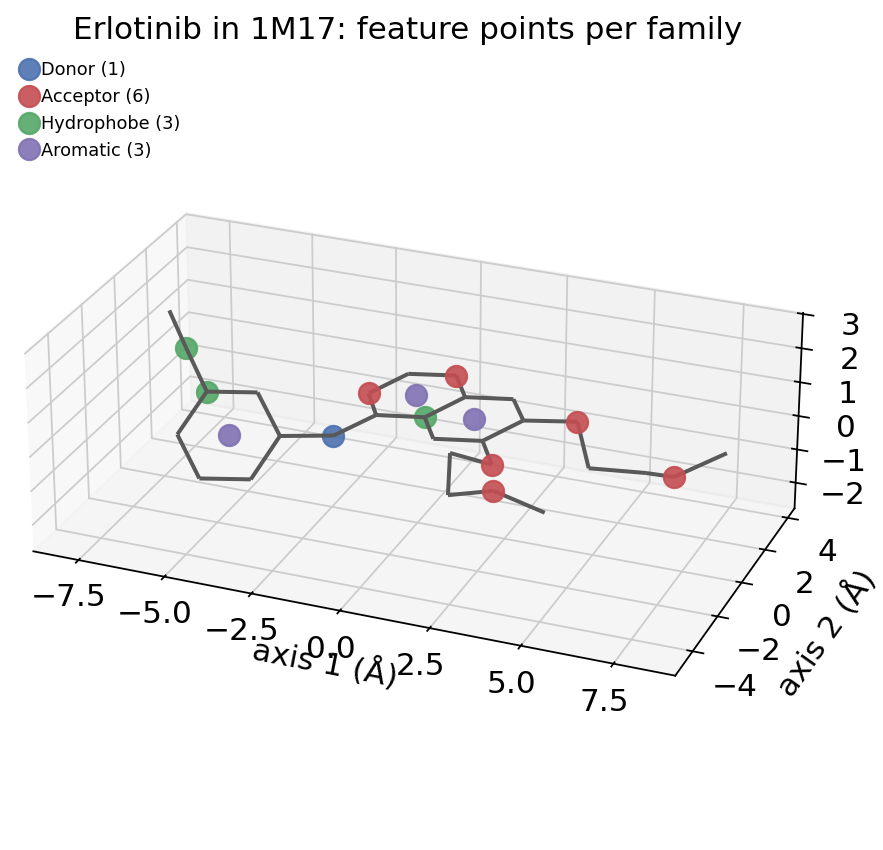

In [4]:
FAMILY_COLORS = {"Donor": "#4C72B0", "Acceptor": "#C44E52",
                 "Hydrophobe": "#55A868", "Aromatic": "#8172B3"}

# All 3D figures are drawn in the ligand's own principal-axis frame, so the
# long axis of the molecule lies along the first plotted axis and the thin
# direction is the third — a flat, readable projection of an elongated ligand.
_ref_xyz = xtal.GetConformer().GetPositions()
_origin = _ref_xyz.mean(axis=0)
_basis = np.linalg.svd(_ref_xyz - _origin, full_matrices=False)[2]

def frame(points):
    """World coordinates (Å) -> the ligand's principal-axis frame (Å)."""
    return (np.asarray(points) - _origin) @ _basis.T

def draw_skeleton(ax, mol, color="0.35", lw=1.8, conf_id=-1):
    """Bonds of a conformer as 3D line segments, in the principal frame."""
    pos = frame(mol.GetConformer(conf_id).GetPositions())
    segs = [[pos[b.GetBeginAtomIdx()], pos[b.GetEndAtomIdx()]] for b in mol.GetBonds()]
    ax.add_collection3d(Line3DCollection(segs, colors=color, linewidths=lw))
    return pos

def set_scale(ax, pts, pad=1.2, elev=26, azim=-68):
    lo, hi = np.min(pts, axis=0) - pad, np.max(pts, axis=0) + pad
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(hi - lo)          # true to scale, not a forced cube
    ax.view_init(elev=elev, azim=azim)
    ax.set(xlabel="axis 1 (Å)", ylabel="axis 2 (Å)", zlabel="axis 3 (Å)")

fig = plt.figure(figsize=(7.2, 5.2), constrained_layout=True)
ax = fig.add_subplot(111, projection="3d")
pos = draw_skeleton(ax, xtal)
for family, points in feats.items():
    ax.scatter(*frame(points).T, s=90, alpha=0.9, label=f"{family} ({len(points)})",
               color=FAMILY_COLORS[family], depthshade=False)
set_scale(ax, pos)
ax.set_title("Erlotinib in 1M17: feature points per family")
ax.legend(loc="upper left", fontsize=8, frameon=False)
plt.show()

The crystal conformer is the familiar L shape: the quinazoline core in the
middle (two aromatic centroids), the 3-ethynylphenyl group reaching into the
back pocket (hydrophobe, far left), and the two methoxyethoxy arms (acceptor
points) trailing towards the solvent.

## 3. From contacts to a model: interaction and excluded volumes

A volume is a plain dictionary — `family`, `center`, `radius`, and an
optional `weight`:

```python
{"family": "Acceptor", "center": [21.7, -2.0, 55.3], "radius": 1.0, "weight": 2.0}
```

We build the model **from the measured contacts** rather than by picking
atoms by hand:

* a donor/acceptor feature with a polar receptor partner within **3.5 Å**
  becomes an H-bond volume (radius 1.0 Å, weight 2.0 — H-bonds are
  directional and expensive to lose);
* an aromatic or hydrophobic feature with at least 6 receptor atoms within
  5 Å becomes a shape volume (radius 1.2 Å, weight 1.0 / 0.5).

The **excluded volumes** are the receptor heavy atoms within 8 Å of the
ligand, each a 1.9 Å sphere — roughly a heavy-atom van der Waals radius, so
"outside every sphere" means "not interpenetrating the protein".

`weight` matters twice: it sets what a volume contributes to the score, and
the search prefers heavily weighted, well-separated volumes as **anchors**.

In [5]:
HBOND_CUTOFF, BURIAL_CUTOFF = 3.5, 6
volumes = []
for family, points in feats.items():
    for point in points:
        if family in ("Donor", "Acceptor"):
            if tree_polar.query(point)[0] <= HBOND_CUTOFF:
                volumes.append({"family": family, "center": point.tolist(),
                                "radius": 1.0, "weight": 2.0})
        elif len(tree_all.query_ball_point(point, 5.0)) >= BURIAL_CUTOFF:
            volumes.append({"family": family, "center": point.tolist(),
                            "radius": 1.2,
                            "weight": 1.0 if family == "Aromatic" else 0.5})

xtal_xyz = xtal.GetConformer().GetPositions()
site_idx = np.unique(np.concatenate(
    [tree_all.query_ball_point(p, 8.0) for p in xtal_xyz]))
excluded = [{"center": prot_xyz[i].tolist(), "radius": 1.9} for i in site_idx]

model = pd.DataFrame(volumes)
model["center"] = model["center"].apply(lambda c: np.round(c, 2).tolist())
print(f"{len(volumes)} interaction volumes, max_score = "
      f"{sum(v['weight'] for v in volumes):.1f}; {len(excluded)} excluded volumes")
model

9 interaction volumes, max_score = 10.5; 243 excluded volumes


       family                 center  radius  weight
0    Acceptor   [18.99, 2.48, 48.54]     1.0     2.0
1    Acceptor   [15.11, 0.17, 53.34]     1.0     2.0
2    Acceptor  [21.75, -2.04, 55.32]     1.0     2.0
3  Hydrophobe   [27.99, 0.09, 53.37]     1.2     0.5
4  Hydrophobe  [22.04, -0.31, 53.57]     1.2     0.5
5  Hydrophobe  [28.84, -1.02, 53.43]     1.2     0.5
6    Aromatic    [27.11, 1.19, 53.3]     1.2     1.0
7    Aromatic  [22.58, -1.12, 54.61]     1.2     1.0
8    Aromatic  [20.67, -0.42, 53.24]     1.2     1.0

Nine interaction volumes with a total weight of 10.5: three acceptors
(weight 2.0 each), three aromatics (1.0) and three hydrophobes (0.5). That
total is the `max_score` every pose is measured against — the score of a
hypothetical pose that reaches every sphere.

243 excluded spheres is a realistic site: the penalty they impose is what
keeps a geometrically perfect pose from being an impossible one.

## 4. `pharmacophore_score` — a tolerance, not a yes/no

The overlap score is **Gaussian-tolerant**: a feature inside its sphere earns
the full weight, and outside it the contribution decays with a width `sigma`
(in Å) — at `sigma` beyond the sphere surface it is down to `1/e`. The
crystal pose must score the maximum here *by construction* (the spheres were
placed on its own feature points), which is precisely what makes it a usable
check: it tells us the scorer and the model agree.

To see what the tolerance means, we translate the crystal pose rigidly away
from the site and rescore it at three values of `sigma`.

crystal pose: score = 10.500 / 10.5
per-volume contributions: [2.  2.  2.  0.5 0.5 0.5 1.  1.  1. ]


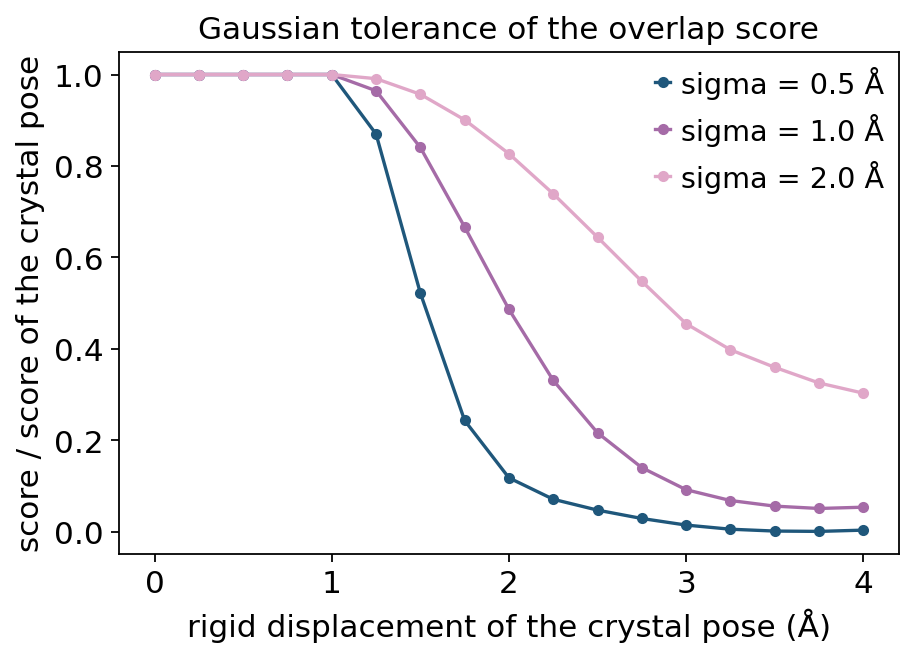

In [6]:
score_xtal, per_volume = ov.mol.pharmacophore_score(xtal, volumes, per_volume=True)
print(f"crystal pose: score = {score_xtal:.3f} / {sum(v['weight'] for v in volumes):.1f}")
print("per-volume contributions:", np.round(per_volume, 3))

direction = np.array([1.0, 0.0, 0.0])
shifts = np.linspace(0, 4, 17)
curves = {}
for sigma in (0.5, 1.0, 2.0):
    vals = []
    for shift in shifts:
        moved = Chem.Mol(xtal)
        conf = moved.GetConformer()
        for i, p in enumerate(xtal_xyz + shift * direction):
            conf.SetAtomPosition(i, p.tolist())
        vals.append(ov.mol.pharmacophore_score(moved, volumes, sigma=sigma))
    curves[sigma] = np.array(vals)

fig, ax = plt.subplots(figsize=(5.6, 4.0), constrained_layout=True)
for sigma, vals in curves.items():
    ax.plot(shifts, vals / score_xtal, "o-", ms=4, label=f"sigma = {sigma} Å")
ax.set(xlabel="rigid displacement of the crystal pose (Å)",
       ylabel="score / score of the crystal pose",
       title="Gaussian tolerance of the overlap score")
ax.legend(frameon=False)
plt.show()

Every per-volume contribution of the crystal pose equals its weight, so the
score is the full 10.5 — the sanity check passes.

The displacement curve shows what `sigma` actually controls. A 1 Å shift
already costs 40–60 % of the score; by 2 Å a tight model (`sigma = 0.5`) has
nothing left, while a loose one (`sigma = 2.0`) still awards a third of the
maximum. **Pass the `sigma` of the model you are reproducing**: a published
model's thresholds are only meaningful with the tolerance it was fitted
with, and a too-generous `sigma` turns the model into a vague shape filter
that ranks decoys above actives.

## 5. `pose_strain_energy` — is the pose physically plausible?

Overlap alone is a trap: a sufficiently distorted conformer can reach almost
any set of spheres. `pose_strain_energy` measures the MMFF94s energy of a
pose **with the heavy atoms frozen** and only the hydrogens relaxed — which
is exactly what a plausibility check on a *stored* pose sees, since an SDF
usually comes back without meaningful hydrogen positions.

The number is only interpretable against a reference, so we compare the
crystal pose with the ligand's own relaxed conformers.

In [7]:
strain_xtal = ov.mol.pose_strain_energy(xtal)

ens = Chem.AddHs(Chem.MolFromSmiles(ERLOTINIB))
params = AllChem.ETKDGv3()
params.randomSeed = 0
AllChem.EmbedMultipleConfs(ens, numConfs=30, params=params)
energies = [e for _, e in AllChem.MMFFOptimizeMoleculeConfs(ens, mmffVariant="MMFF94s",
                                                            maxIters=2000)]
print(f"crystal pose, frozen heavy atoms : {strain_xtal:8.1f} kcal/mol")
print(f"relaxed ensemble (n=30)          : {min(energies):8.1f} (best) /"
      f" {np.median(energies):.1f} (median) / {max(energies):.1f} (worst) kcal/mol")
print(f"strain of the deposited geometry : {strain_xtal - min(energies):8.1f} kcal/mol")

crystal pose, frozen heavy atoms :    117.1 kcal/mol
relaxed ensemble (n=30)          :     58.9 (best) / 58.9 (median) / 58.9 (worst) kcal/mol
strain of the deposited geometry :     58.2 kcal/mol


The deposited geometry sits ~59 kcal/mol above the ligand's best relaxed
conformer. That is **not** a defect of the function — it is what crystal
ligand coordinates look like: they are fitted to density with restraints
that are chemically approximate, bond lengths and angles are a little off,
and a frozen-heavy-atom force-field energy picks all of that up. The lesson
for alignment is the one the module acts on: compare strain **relative to
the same ligand's own relaxed ensemble**, never as an absolute number, and
never across molecules of different size. `pharmacophore_align` does this
automatically with `strain_tolerance='auto'`.

## 6. `pharmacophore_align` — rebuild the pose from the SMILES alone

Now the real test. We throw away the crystal coordinates and give the aligner
only (i) erlotinib's SMILES string, (ii) the nine interaction volumes and
(iii) the 243 excluded spheres. It must generate its own conformers, guess
which atom belongs in which sphere, and place a rigid body.

Because we know the answer, we can measure the error. Two RMSDs are easy to
confuse:

* `rdMolAlign.CalcRMS(pose, xtal)` — symmetry-aware RMSD **in place**, i.e.
  the pose-prediction error. This is the number to report.
* `AllChem.GetBestRMS(pose, xtal)` — superimposes the two molecules first, so
  it measures *conformer shape* similarity and is blind to misplacement.

In [8]:
pose = ov.mol.pharmacophore_align(
    ERLOTINIB, volumes, excluded_volumes=excluded,
    n_confs=120, seed=0, time_budget=240, n_threads=2)

ref, prb = Chem.RemoveHs(xtal), Chem.RemoveHs(pose.mol)
rmsd_in_place = rdMolAlign.CalcRMS(prb, ref)
rmsd_shape = AllChem.GetBestRMS(Chem.Mol(prb), ref)

print(pd.Series(pose.to_dict()).round(3).to_string())
print(f"\nRMSD to the crystal pose, in place (CalcRMS) : {rmsd_in_place:.2f} Å")
print(f"conformer-shape RMSD (GetBestRMS)            : {rmsd_shape:.2f} Å")

score                8.748
max_score           10.500
score_fraction       0.833
clash_depth          0.000
conformer_energy    57.684
strain              -0.000
n_conformers         1.000

RMSD to the crystal pose, in place (CalcRMS) : 1.57 Å
conformer-shape RMSD (GetBestRMS)            : 1.24 Å


The pose reaches **83 % of the maximum overlap**, has `clash_depth = 0`
(no atom inside an excluded sphere) and essentially zero strain — it is a
rigid placement of a relaxed conformer, which is the module's design.

The in-place RMSD of ~1.5 Å is a **successful redocking-quality result**: the
usual criterion in the docking literature is 2 Å, and here it was reached
with no receptor, no grid and no empirical scoring function — only nine
spheres and a shape constraint. The conformer-shape RMSD is lower (~1.2 Å),
which tells us most of the remaining error is a small rigid-body offset
rather than the wrong conformer.

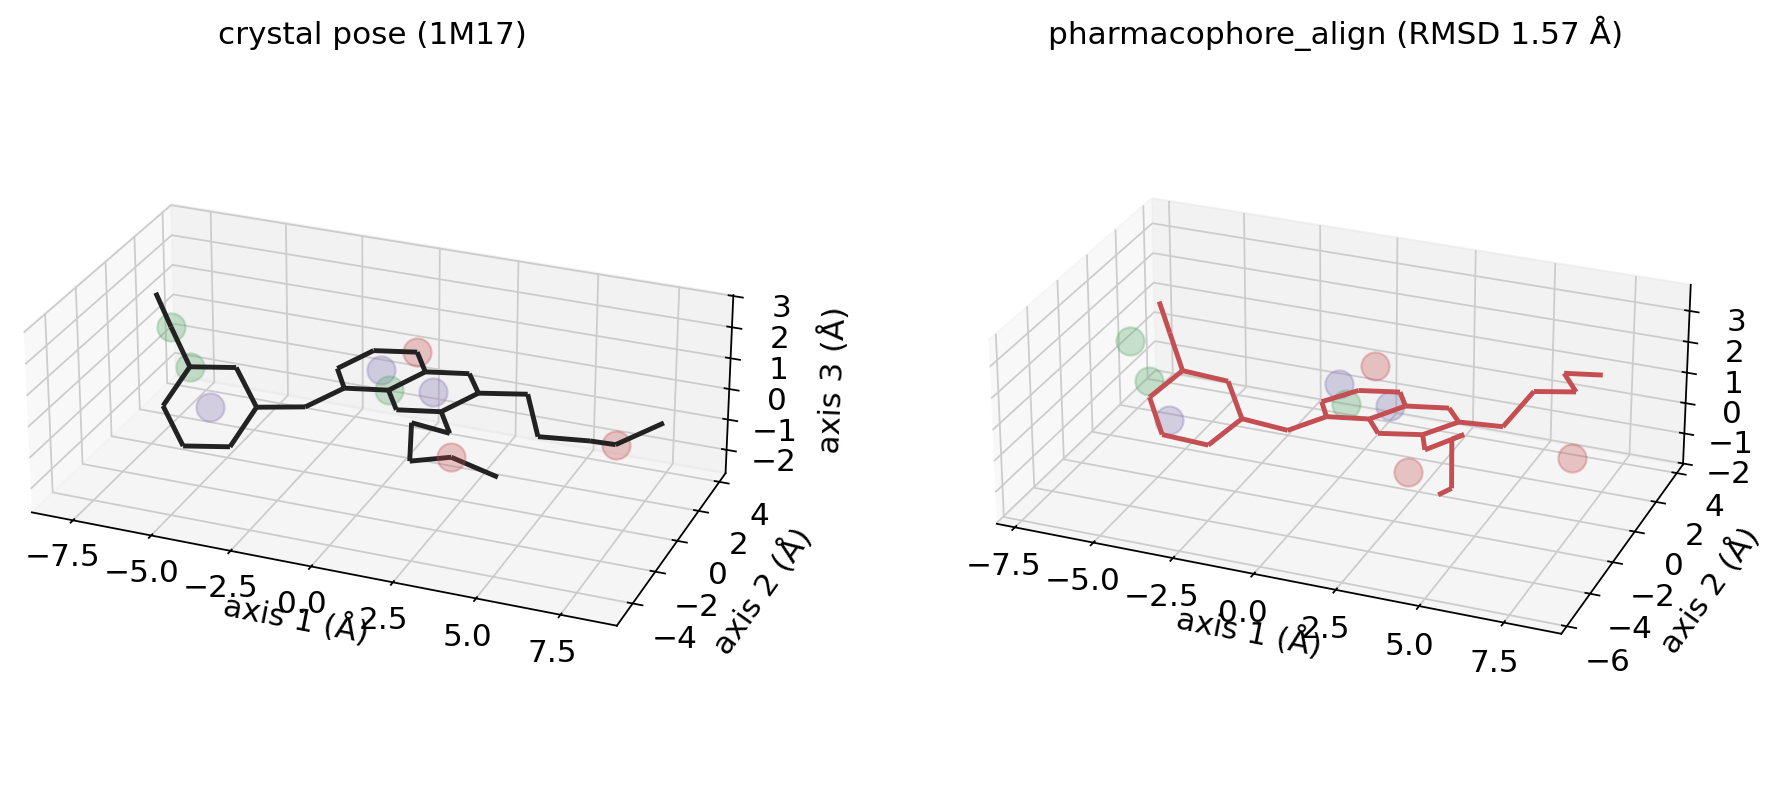

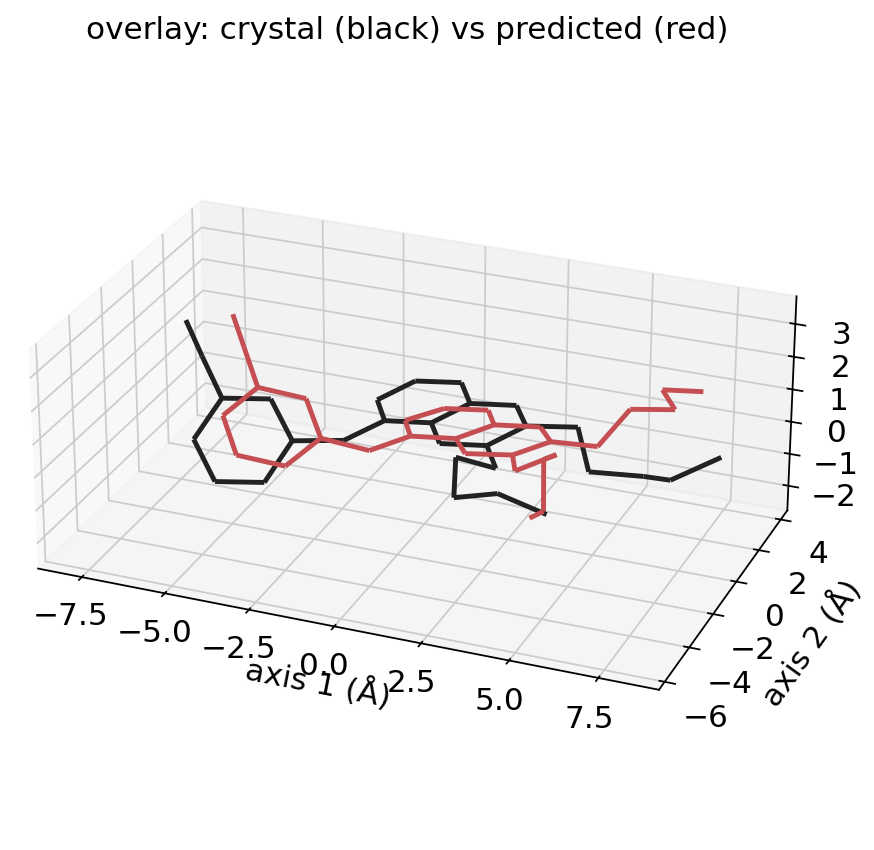

In [9]:
centers = np.array([v["center"] for v in volumes])
fams = [v["family"] for v in volumes]

centers_f = frame(centers)

fig = plt.figure(figsize=(12.0, 4.8), constrained_layout=True)
for k, (title, mol, color) in enumerate(
        [("crystal pose (1M17)", ref, "#222222"),
         (f"pharmacophore_align (RMSD {rmsd_in_place:.2f} Å)", prb, "#C44E52")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    pts = draw_skeleton(ax, mol, color=color, lw=2.2)
    for c, f in zip(centers_f, fams):
        ax.scatter(*c, s=160, alpha=0.3, color=FAMILY_COLORS[f], depthshade=False)
    set_scale(ax, np.vstack([pts, centers_f]))
    ax.set_title(title)
plt.show()

fig = plt.figure(figsize=(7.2, 5.2), constrained_layout=True)
ax = fig.add_subplot(111, projection="3d")
a = draw_skeleton(ax, ref, color="#222222", lw=2.2)
b = draw_skeleton(ax, prb, color="#C44E52", lw=2.2)
set_scale(ax, np.vstack([a, b]))
ax.set_title("overlay: crystal (black) vs predicted (red)")
plt.show()

Side by side, the predicted pose occupies the same volumes in the same
orientation: quinazoline in the middle, alkynylphenyl in the back pocket, the
ether arms towards the solvent. The overlay shows where the ~1.5 Å comes
from — the flexible methoxyethoxy tails, which the model constrains only
loosely because their acceptor spheres are at the solvent-exposed mouth.

### What the excluded volumes buy

Dropping them lets the search chase overlap without caring about the
receptor. We measure the deepest penetration into the 1.9 Å receptor spheres
for both poses.

In [10]:
pose_free = ov.mol.pharmacophore_align(
    ERLOTINIB, volumes, n_confs=120, seed=0, time_budget=240, n_threads=2)

def deepest_penetration(mol, spheres):
    """Worst (radius - distance) over atoms; negative = clearance in Å."""
    cen = np.array([s["center"] for s in spheres])
    rad = np.array([s["radius"] for s in spheres])
    d = np.linalg.norm(mol.GetConformer().GetPositions()[:, None, :] - cen[None], axis=2)
    return float(np.max((rad[None] - d).max(axis=1)))

prb_free = Chem.RemoveHs(pose_free.mol)
comparison = pd.DataFrame([
    {"run": "with excluded volumes", "score": pose.score,
     "score_fraction": pose.score_fraction,
     "clash_depth": pose.clash_depth,
     "deepest_penetration_A": deepest_penetration(prb, excluded),
     "rmsd_to_crystal_A": rmsd_in_place},
    {"run": "no excluded volumes", "score": pose_free.score,
     "score_fraction": pose_free.score_fraction,
     "clash_depth": pose_free.clash_depth,
     "deepest_penetration_A": deepest_penetration(prb_free, excluded),
     "rmsd_to_crystal_A": rdMolAlign.CalcRMS(prb_free, ref)},
]).set_index("run")
comparison.round(3)

                       score  score_fraction  clash_depth  \
run                                                         
with excluded volumes  8.748           0.833          0.0   
no excluded volumes    9.613           0.916          0.0   

                       deepest_penetration_A  rmsd_to_crystal_A  
run                                                              
with excluded volumes                 -0.232              1.574  
no excluded volumes                   -0.017              1.595  

Without the shape constraint the overlap is **higher** (9.6 vs 8.8) — the
search is free to press features into their spheres — and the pose ends up
grazing the receptor: its worst atom clears the 1.9 Å spheres by only
0.02 Å, versus 0.23 Å for the constrained pose, whose RMSD to the crystal is
also slightly better. Note also that `clash_depth` is reported as 0.0 in the
unconstrained run: with no excluded volumes there is nothing to clash with,
so **a zero `clash_depth` only means something when excluded volumes were
supplied**.

This is the general lesson of receptor-free pose generation: overlap is a
necessary but not sufficient criterion, and the excluded volumes (plus the
strain budget) are what keep the best-scoring pose from being an impossible
one.

## 7. `align_pharmacophore_set` — a series through a model

In practice you have a series, not one ligand. `align_pharmacophore_set`
takes a `{identifier: spec}` mapping, where each spec carries its own
ligand (`smiles`), its own `interaction_volumes` and `excluded_volumes`, and
optionally per-entry `align` overrides. It returns one record per entry and
can write all poses to a single SDF.

We run four ligands against the full nine-volume model: the native
erlotinib, the second-generation analogue **gefitinib**, the bare
**4-anilinoquinazoline** scaffold, and **ethanol** as a negative control.

In [11]:
series = {
    "erlotinib":           ERLOTINIB,
    "gefitinib":           "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1",
    "4-anilinoquinazoline": "c1ccc(Nc2ncnc3ccccc23)cc1",
    "ethanol":             "CCO",
}
specs_full = {name: {"smiles": smi,
                     "interaction_volumes": volumes,
                     "excluded_volumes": excluded}
              for name, smi in series.items()}

records_full = ov.mol.align_pharmacophore_set(
    specs_full, output="poses_full_model.sdf",
    n_confs=100, seed=0, time_budget=120, n_threads=2)

pd.DataFrame([{k: v for k, v in r.items() if k != "mol"} for r in records_full]).round(3)

                     id     ok  score  max_score  score_fraction  clash_depth  \
0             erlotinib   True  8.748       10.5           0.833          0.0   
1             gefitinib   True  7.703       10.5           0.734          0.0   
2  4-anilinoquinazoline  False    NaN        NaN             NaN          NaN   
3               ethanol  False    NaN        NaN             NaN          NaN   

   conformer_energy  strain  n_conformers                    error  
0            57.684    -0.0           1.0                      NaN  
1            95.147    -0.0           1.0                      NaN  
2               NaN     NaN           NaN  no pose could be placed  
3               NaN     NaN           NaN  no pose could be placed  

Two ligands are placed and two are **refused**, with
`ok = False` and `error = 'no pose could be placed'` rather than a
fabricated pose. That refusal is the correct answer: the model was derived
from erlotinib and asks for three acceptors, two of which are the ether
oxygens of its solubilising arms. Neither the bare scaffold nor ethanol has
such an oxygen in a reachable position, so no feasible correspondence
exists. Gefitinib, which does carry an ether-rich side chain, reaches 73 %
of the maximum (`score_fraction = 0.73`).

A model is therefore only as transferable as the chemistry it was built
from. Applying it to smaller analogues means **reducing it to the volumes
that the shared scaffold can reach** — here, the hinge acceptor plus the
aromatic volumes.

In [12]:
reduced = [v for v in volumes
           if v["family"] == "Aromatic"
           or (v["family"] == "Acceptor"
               and tree_polar.query(np.array(v["center"]))[0] < 3.0)]
print(f"reduced model: {len(reduced)} volumes, max_score = "
      f"{sum(v['weight'] for v in reduced):.1f} "
      f"({[v['family'] for v in reduced]})")

specs_reduced = {name: {"smiles": smi,
                        "interaction_volumes": reduced,
                        "excluded_volumes": excluded}
                 for name, smi in series.items()}

records_reduced = ov.mol.align_pharmacophore_set(
    specs_reduced, output="poses_reduced_model.sdf",
    n_confs=100, seed=0, time_budget=120, n_threads=2)

pd.DataFrame([{k: v for k, v in r.items() if k != "mol"}
              for r in records_reduced]).round(3)

reduced model: 4 volumes, max_score = 5.0 (['Acceptor', 'Aromatic', 'Aromatic', 'Aromatic'])


                     id    ok  score  max_score  score_fraction  clash_depth  \
0             erlotinib  True   5.00        5.0           1.000          0.0   
1             gefitinib  True   4.99        5.0           0.998          0.0   
2  4-anilinoquinazoline  True   5.00        5.0           1.000          0.0   
3               ethanol  True   2.00        5.0           0.400          0.0   

   conformer_energy  strain  n_conformers  
0            57.684    -0.0             1  
1            95.147    -0.0             1  
2             8.774    -0.0             1  
3            -1.337    -0.0             1  

On the scaffold-sized model (the Met769 hinge acceptor at weight 2.0 plus the
three aromatic volumes, `max_score = 5.0`) the ranking becomes chemically
sensible:

* **4-anilinoquinazoline reaches `score_fraction = 1.00`** — the bare
  scaffold already satisfies everything the reduced model asks for, which is
  the structural reason this scaffold is an EGFR pharmacophore in the first
  place;
* erlotinib and gefitinib also satisfy it (their extra chemistry is now
  unscored);
* **ethanol stops at 0.40** — it can donate/accept at the hinge sphere
  (weight 2.0 of 5.0) and has no aromatic ring at all, so 60 % of the model
  is unreachable for it. The score separates a scaffold from a non-scaffold
  without any receptor information.

The poses were written to SDF with their properties, which is how they leave
the notebook and enter a docking, MM-GBSA or visualisation step.

In [13]:
written = Chem.SDMolSupplier("poses_reduced_model.sdf", removeHs=False)
for mol in written:
    if mol is None:
        continue
    props = mol.GetPropsAsDict()
    print(f"{props.get('ID', '?'):>22}  atoms={mol.GetNumAtoms():>3}  "
          + "  ".join(f"{k}={float(v):.3f}" for k, v in props.items()
                      if k in ("PH4_SCORE", "PH4_SCORE_FRACTION", "PH4_CLASH_DEPTH")))

             erlotinib  atoms= 29  PH4_SCORE=5.000  PH4_SCORE_FRACTION=1.000  PH4_CLASH_DEPTH=0.000
             gefitinib  atoms= 31  PH4_SCORE=4.990  PH4_SCORE_FRACTION=0.998  PH4_CLASH_DEPTH=0.000
  4-anilinoquinazoline  atoms= 17  PH4_SCORE=5.000  PH4_SCORE_FRACTION=1.000  PH4_CLASH_DEPTH=0.000
               ethanol  atoms=  3  PH4_SCORE=2.000  PH4_SCORE_FRACTION=0.400  PH4_CLASH_DEPTH=0.000


Each record carries its identifier in the `ID` property (configurable with
`id_prop`) and the alignment metrics under `PH4_*` properties, so the SDF is
self-describing — `properties=False` turns that off, and
`keep_hydrogens=True` writes explicit hydrogens (heavy-atom geometry is
identical either way).

## 8. Pitfalls

* **Protonation and tautomers decide the families.** The feature factory reads
  the molecule you give it. An imidazole drawn in the other tautomer swaps a
  donor for an acceptor, and a carboxylic acid drawn neutral keeps a donor
  that is absent at pH 7.4. Prepare the ligand at the relevant pH *before*
  aligning, and state what you did.
* **Report in-place RMSD, not `GetBestRMS`.** `GetBestRMS` superimposes before
  measuring, so it cannot see a misplaced pose. Use
  `rdMolAlign.CalcRMS`, which is symmetry-aware (it matches the molecular
  graph automorphisms, so a flipped phenyl does not inflate the error) but
  does not realign.
* **Overlap is not the whole objective.** A high score with visible strain, or
  with no excluded volumes supplied, is not evidence of a plausible pose.
  Report `score_fraction`, `clash_depth` and `strain` together; use
  `min_score_fraction` when you want the *least strained* pose that reaches a
  given overlap rather than the best-scoring one.
* **Strain is only meaningful relative to the same molecule.** A rigid
  bicyclic has a few kcal/mol of conformational range, a macrocycle has tens.
  Keep `strain_tolerance='auto'` (calibrated on the ligand's own relaxed
  ensemble) unless you are reproducing a published budget, and never compare
  raw energies across molecules of different size — as section 5 showed, even
  a crystal pose is tens of kcal/mol above its relaxed minimum.
* **Excluded-volume radius is a modelling choice.** Too small (1.0 Å) and the
  constraint does nothing; too large (> 2.2 Å) and no pose fits at all.
  Around 1.5–1.9 Å per receptor heavy atom is a reasonable shape shell; use
  `clash_tolerance` to allow a specified penetration instead of inflating or
  shrinking the radii, and remember that `clash_depth = 0` is vacuous if no
  excluded volumes were passed.
* **Flexibility lives entirely in the ensemble.** The placement is rigid, so a
  ligand with many rotatable bonds needs a larger `n_confs` (the default 200;
  macrocycles more). If a plausible ligand cannot be placed, raise `n_confs`
  and `time_budget` before loosening the model.
* **A refusal is information.** `'no pose could be placed'` means no feasible
  correspondence survived the family, topology and clash filters — usually
  that the model asks for chemistry the ligand does not have. Reduce the
  model to the shared pharmacophore instead of forcing a fit.
* **Reproducibility.** `seed` fixes both the embedding and the rigid-body
  search, and `time_budget` makes the search *wall-clock dependent*: a run on
  a busier machine can explore less. Record both, and `n_confs`, with any
  reported pose.
* **Optional visualisation.** `rdkit.Chem.Draw` (2D depictions) and `py3Dmol`
  (interactive 3D, used by the other `ov.mol` tutorials) are not required
  here — all figures above are matplotlib, so the notebook runs in a
  headless environment without the X libraries RDKit's drawing code needs.

## 9. References

* Stamos J., Sliwkowski M.X., Eigenbrot C. (2002) *Structure of the epidermal
  growth factor receptor kinase domain alone and in complex with a
  4-anilinoquinazoline inhibitor.* **J. Biol. Chem.** 277:46265–46272.
  doi:10.1074/jbc.M207135200 — PDB **1M17**, the complex used here.
* Wolber G., Langer T. (2005) *LigandScout: 3-D pharmacophores derived from
  protein-bound ligands and their use as virtual screening filters.*
  **J. Chem. Inf. Model.** 45:160–169. doi:10.1021/ci049885e — deriving a
  pharmacophore from a co-crystal ligand, the workflow of section 3.
* Dixon S.L. *et al.* (2006) *PHASE: a new engine for pharmacophore
  perception, 3D QSAR model development, and 3D database screening.*
  **J. Comput. Aided Mol. Des.** 20:647–671. doi:10.1007/s10822-006-9087-6 —
  Gaussian-tolerance site matching and excluded volumes.
* Riniker S., Landrum G.A. (2015) *Better informed distance geometry: using
  what we know to improve conformation generation.* **J. Chem. Inf. Model.**
  55:2562–2574. doi:10.1021/acs.jcim.5b00654 — the ETKDG embedding behind
  `n_confs`.
* Halgren T.A. (1996) *Merck molecular force field. I.* **J. Comput. Chem.**
  17:490–519. doi:10.1002/(SICI)1096-987X(199604)17:5/6<490::AID-JCC1>3.0.CO;2-P
  — the MMFF94/MMFF94s energies used for minimisation and strain.
* Kabsch W. (1976) *A solution for the best rotation to relate two sets of
  vectors.* **Acta Crystallogr. A** 32:922–923. doi:10.1107/S0567739476001873
  — the superposition behind the anchor correspondence.
* Landrum G. *RDKit: Open-source cheminformatics.* https://www.rdkit.org —
  feature definitions (`BaseFeatures.fdef`), conformer generation, symmetry-aware
  RMSD.